In [2]:
# MANIPULASI DATA & UTILITAS
import pandas as pd         
import numpy as np          
from tqdm import tqdm      
from collections import defaultdict 

# PREPROCESSING TEKS (NATURAL LANGUAGE PROCESSING - NLP)
import re                  
import regex               
import nltk                 
from nltk.corpus import stopwords, words 
from nltk.tokenize import word_tokenize  

# ASSOCIATION RULE MINING (MLXTEND)
from mlxtend.preprocessing import TransactionEncoder 
from mlxtend.frequent_patterns import fpgrowth, association_rules 

# PEMBOBOTAN FITUR, PENYEIMBANGAN & PEMBAGIAN DATA
from sklearn.model_selection import train_test_split  
from sklearn.feature_extraction.text import TfidfVectorizer 
from imblearn.over_sampling import SMOTE              

# PEMODELAN MACHINE LEARNING (CLASSIFICATION)
from sklearn.tree import DecisionTreeClassifier 

# EVALUASI MODEL
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# VISUALISASI DATA
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv(r"D:\Download\doc\SK_WIDIASIH\dataset_kompas\dataset_kompas_gabungan_bersih.csv")

In [3]:
df

,Keyword,Halaman Tag,Judul Berita,Link Berita,Isi Berita
0,jasad,51,Bocah yang Jasadnya Terbungkus Sarung Tewas Di...,https://megapolitan.kompas.com/read/2025/01/13...,"JAKARTA, KOMPAS.com - Pasangan pengemis bernam..."
1,jasad,51,Orangtua Bocah Tewas dalam Sarung Sering Aniay...,https://megapolitan.kompas.com/read/2025/01/13...,"JAKARTA, KOMPAS.com - Sinta Dewi (22) dan Aidi..."
2,jasad,51,Orangtua Bocah Tewas dalam Sarung Aniaya Anakn...,https://megapolitan.kompas.com/read/2025/01/13...,"JAKARTA, KOMPAS.com - Dua pengemis bernama Sin..."
3,jasad,51,Orangtua Bocah Tewas Terbungkus Sarung di Beka...,https://megapolitan.kompas.com/read/2025/01/13...,"JAKARTA, KOMPAS.com - Balita berinisial RMR (3..."
4,jasad,51,"Motif Orangtua Bunuh Anak di Bekasi, Emosi kar...",https://megapolitan.kompas.com/read/2025/01/13...,"JAKARTA, KOMPAS.com - Polisi mengungkapkan, or..."
...,...,...,...,...,...
103182,uang palsu,84,20 Miliar Uang Palsu Diamankan Polisi,https://nasional.kompas.com/read/xml/2008/07/0...,"JAKARTA, SELASA - Aparat Kepolisian Resor Metr..."
103183,uang palsu,84,Li Siang Berkaraoke dengan Uang Palsu,https://regional.kompas.com/read/xml/2008/06/2...,"PALEMBANG, SELASA - Sastra Jaya (41), warga Ja..."
103184,uang palsu,85,BI: Waspadai Uang Palsu untuk Pilkada Jatim,https://www.kompas.com/read/xml/2008/05/30/134...,NaN
103185,uang palsu,85,Polisi Sita Uang Palsu Senilai 284.000 dollar AS,https://regional.kompas.com/read/xml/2008/02/2...,"BANDUNG, SENIN- Kepolisian Wilayah Kota Besar ..."


In [4]:
df.columns = df.columns.str.strip()
df.rename(columns={
    'Keyword': 'keyword',
    'Halaman Tag': 'halaman_tag',
    'Judul Berita': 'judul_berita',
    'Link Berita': 'link_berita',
    'Isi Berita': 'isi_berita'
}, inplace=True)

# Cek Data

In [5]:
print("Jumlah baris data:")
jumlah_baris = len(df)
print(f"   Total baris data: {jumlah_baris}")

Jumlah baris data:
   Total baris data: 103187


In [6]:
jumlah_duplikasi = df.duplicated().sum()
print("Cek data duplikasi:")
print(f"   Jumlah baris duplikat: {jumlah_duplikasi}")

Cek data duplikasi:
   Jumlah baris duplikat: 0


In [7]:
print("Cek data kosong (Missing Values):")
data_kosong = df.isnull().sum()
print(data_kosong)

Cek data kosong (Missing Values):
keyword           0
halaman_tag       0
judul_berita      0
link_berita       0
isi_berita      865
dtype: int64


# Data Preprosesing

In [6]:
df.dropna(subset=['isi_berita'], inplace=True)

In [9]:
print("Cek data kosong (Missing Values):")
data_kosong = df.isnull().sum()
print(data_kosong)

Cek data kosong (Missing Values):
keyword         0
halaman_tag     0
judul_berita    0
link_berita     0
isi_berita      0
dtype: int64


In [10]:
print(f"Jumlah baris setelah data missing dihapus: {len(df)}")

Jumlah baris setelah data missing dihapus: 102322


In [7]:
extra_stopwords = [
    'yang', 'untuk', 'akan', 'with', 'adalah', 'bahwa', 'tersebut', 'kompas', 'com', 'KOMPAS.com', 
    'jakarta', 'artikel', 'berita', 'selengkapnya', 
    'klik', 'oleh', 'karena', 'seperti', 'kami', 'berkomitmen fakta jernih tepercaya','anda',
    'juga', 'dari', 'atau', 'tetapi', 'namun', 'serta',
    'bagi', 'para', 'hingga', 'yakni',  'terhadap', 'sementara', 
    'scroll', 'continue', 'content', 'advertisement', 'tonton', 'kompas.com','baca','dapatkan', 
    'update', 'halaman', 'indonesia', 'kompastekno', 'dihimpun','kompascom', 'kreatif',
    'proglobal', 'tren', 'regional', 'megapolitan', 'nasional']
stop_indonesia = set(stopwords.words('indonesian') + extra_stopwords)
protected_words = {
    'kdrt', 'otk', 'tkp', 'bom', 'vcs', 'art', 'bb', 'abu', 'sh', 'sab', 'uu','ite', 'diri','anak',
    'hiv', 'pns', 'kpk', 'tni', 'pol', 'kkb', 'opm', 'it', 'kost', 'kos', 'pp','aids','di','ke','ig','fb',
    'mall', 'dini', 'pukul', 'jam', 'gas', 'sel', 'bo', 'video', 'foto','hari','di','ke','sampai','sesama','sama','dengan',
    'rs', 'wa', 'tpu', 'sd', 'smp', 'sma', 'tk', 'rw', 'rt','tidak','tak','dalam','tua'}

def clean_text(text):
    if not isinstance(text, str): return "" 
    footer_pattern = r'\b(simak\s+video|baca\s+juga|tonton\s+juga|selengkapnya|baca\s+berita\s+terkait|dapatkan\s+update|download\s+aplikasi)\b.*'
    text = re.sub(footer_pattern, ' ', text, flags=re.IGNORECASE | re.DOTALL)
    text = re.sub(r'http\S+|www\S+', ' ', text)
    text = text.lower() 
    text = re.sub(r'[^a-z0-9\s:.]', ' ', text) 
    text = re.sub(r'\s+', ' ', text).strip() 
    
    clean_words = []
    for w in word_tokenize(text):
        w = w.strip('.')
        is_time = any(char.isdigit() for char in w)
        if is_time or (w in protected_words) or (w not in stop_indonesia and len(w) > 2):
            clean_words.append(w)           
    return " ".join(clean_words)
tqdm.pandas()
df['text_clean'] = df['isi_berita'].progress_apply(clean_text)
df = df[(df['text_clean'].apply(lambda x: len(str(x).split())) > 100) & (df['text_clean'].str.len() > 300)].reset_index(drop=True)

100%|██████████| 102322/102322 [12:26<00:00, 137.10it/s]


In [8]:
pd.set_option('display.max_colwidth', None)
kolom_berita_asli = 'isi_berita' 
df[[kolom_berita_asli, 'text_clean']].head(3)

,isi_berita,text_clean
0,"JAKARTA, KOMPAS.com - Pasangan pengemis bernama Sinta Dewi (22) dan Aidil Zacky Rahman (19) menganiaya anak mereka berinisial RMR (3) hingga tewas saat balita itu sedang sakit. Kasubdit Resmob Ditreskrimum Polda Metro Jaya AKBP Ressa Fiardi Marasabessy mengungkapkan, RMR menderita muntaber sebelum ia tewas di tangan orangtuanya. “Ternyata anak itu sudah muntaber seminggu,” kata Ressa saat dikonfirmasi, Senin (13/1/2025). RMR disebut muntah-muntah usai korban mengonsumsi susu pemberian orang lain. “Indikasinya sakit karena muntah-muntah habis minum susu,” ujar dia. Adapun RMR tewas dianiaya Sinta dan Aidil karena orangtuanya emosi setelah korban muntah di teras minimarket, tempat mereka mengemis setiap hari. Seorang karyawan menegur Sinta dan Aidil agar RMR tidak muntah lagi di teras jika masih ingin mengemis di minimarket. Diberitakan sebelumnya, jasad bocah laki-laki yang diduga berusia lima tahun ditemukan di sebuah ruko kosong di Jalan Inspeksi Kalimalang, Senin (6/1/2025). Jasad tersebut diduga dibuang oleh kedua orangtuanya yang sempat buron. Berdasarkan pemeriksaan kepolisian, terdapat sejumlah luka di tubuh bocah tersebut. Luka-luka ini antara lain, lecet di pipi sebelah kiri, memar di kuping sebelah kiri, serta luka seperti sundutan rokok di bagian pantat, pipi, dan kaki. Selain itu, terdapat benjolan di bagian kepala tengah dan belakang, serta luka lebam di sekitar pinggang atas sebelah kanan. Setelah penemuan ini, polisi menangkap orangtua korban bernama Sinta Dewi dan Aidil Zacky Rahman pada Rabu (8/1/2025) malam. Keduanya dijerat dengan Pasal 76C juncto Pasal 80 ayat (3) Undang-Undang Nomor 35 Tahun 2014 tentang Perlindungan Anak, dan/atau Pasal 170 ayat (2) ke-3 KUHP, serta/atau Pasal 351 ayat (3) KUHP.",pasangan pengemis bernama sinta dewi 22 aidil zacky rahman 19 menganiaya anak berinisial rmr 3 tewas balita sakit kasubdit resmob ditreskrimum polda metro jaya akbp ressa fiardi marasabessy rmr menderita muntaber tewas di tangan orangtuanya anak muntaber seminggu ressa dikonfirmasi senin 13 1 2025 rmr muntah muntah korban mengonsumsi susu pemberian orang indikasinya sakit muntah muntah habis minum susu rmr tewas dianiaya sinta aidil orangtuanya emosi korban muntah di teras minimarket mengemis hari karyawan menegur sinta aidil rmr tidak muntah di teras mengemis di minimarket diberitakan jasad bocah laki laki diduga berusia ditemukan di ruko kosong di jalan inspeksi kalimalang senin 6 1 2025 jasad diduga dibuang orangtuanya buron berdasarkan pemeriksaan kepolisian luka di tubuh bocah luka luka lecet di pipi sebelah kiri memar di kuping sebelah kiri luka sundutan rokok di pantat pipi kaki benjolan di kepala luka lebam di pinggang sebelah kanan penemuan polisi menangkap orangtua korban bernama sinta dewi aidil zacky rahman rabu 8 1 2025 malam dijerat dengan pasal 76c juncto pasal 80 ayat 3 undang undang nomor 35 2014 perlindungan anak pasal 170 ayat 2 ke 3 kuhp pasal 351 ayat 3 kuhp
1,"JAKARTA, KOMPAS.com - Sinta Dewi (22) dan Aidil Zacky Rahman (19), dua pengemis di Tambun Selatan, Kabupaten Bekasi, kerap menganiaya anaknya berinisial RMR (3) sebelum ditemukan tewas di sebuah ruko kosong, Minggu (7/1/2025). Direktur Reserse Kriminal Umum Polda Metro Jaya Kombes Wira Satya Triputra menjelaskan, penganiayaan tersebut dipicu oleh kebiasaan RMR yang kerap buang air besar (BAB) di celana. “Sebelumnya anak korban sering mendapat kekerasan dari para tersangka dengan cara dipukul di bagian kepala, badan, dan disundut rokok karena buang air besar di celana, tidak pernah memberitahukan walaupun sudah dibilang berkali-kali,” ungkap Wira di Polda Metro Jaya, Senin (13/1/2025). RMR diduga tewas setelah dianiaya oleh Sinta dan Aidil di ruko kosong, tempat mereka beristirahat sehari-hari. Dugaan penganiayaan bermula saat Sinta dan RMR berangkat dari ruko menuju sebuah minimarket di wilayah Tambun Selatan untuk mengemis pada Sabtu (5/1/2025) malam. ""Sekitar pukul 20.45 WIB, korban muntah di teras minimarke

### True & False Kriminal

In [14]:
skor_tinggi = {k: 40 for k in [
    'fantasi sedarah','pencuri mobil','alasan pencurian','dihajar warga','dihajar berkali kali','korban remas payudara','korban pembegalan payudara','pembegalan payudara','dirundung','koma dirundung','penyiraman air aki','menyiram pelanggannya','dicegat','korban penipuan','menyentuh payudaranya','penjarahan muatan','aksi tak terpuji','warga jarah muatannya','korban peredaran uang','uang palsu','memanfaatkan kelemahan','menggelapkan dana tabungan','digelapkan salah guru','digelapkan','penggelapan','dikdrt','suami aniaya istri','anak dianiaya','mengalami luka baret','kacamatanya pecah dipukul','dipukul petugas transjakarta','korban penipuan','komplotan sna kepala','mendalami dugaan penyalahgunaan',
    'mutilasi', 'rudapaksa', 'digorok', 'tewas mengenaskan', 'tombak menancap', 'dianiaya', 'babak belur', 'aksi kriminal',
    'leher digorok', 'luka bacokan', 'tawuran', 'carok', 'menangkap', 'napi melarikan diri',  'menjebol terali sel', 'penyiraman air keras', 'menyerang', 'mengamankan', 'tindakan kekerasan', 
    'pembunuhan massal', 'penembakan brutal', 'penikaman', 'pembacokan', 'penjagalan', 'pelecehan oral seks', 
    'dikeroyok', 'pengeroyokan', 'pembobolan', 'dibobol', 'raib', 'diembat', 'menganiaya', 'menusuk', 
    'membacok', 'penyiksaan', 'disiksa', 'pembunuhan', 'tersangka pembacokan', 'dijambret', 'memerkosa', 
    'cabuli', 'ditembak kelompok kriminal', 'tersangka diamankan', 'dibunuh', 'penembakan misterius', 
    'dihabisi', 'kematian tragic', 'dibunuh pelanggan', 'nyawa melayang', 'tewas dibantai', 'tewas digorok', 
    'terpergok kamera', 'pelaku keributan', 'penghilangan nyawa', 'pengeroyokan maut', 'bentrok berdarah', 
    'ditembak', 'main hakim sendiri', 'penganiayaan berat', 'luka tusuk', 'luka sayat', 'ditembak mati', 
    'kronologi penembakan', 'upaya jemput paksa', 'penangkapan', 'pelaku berhasil tangkap', 
    'pelaku berhasil ditangkap', 'pelaku gelap mata', 'pelaku melancarkan aksinya', 'timah panas', 
    'diringkus', 'penemuan mayat pelaku', 'aksi main hakim', 'pencabulan berlanjut', 'bersimbah darah', 
    'membakar tubuh korban', 'dibegal', 'dicuri', 'pemerkosaan', 'diperkosa', 'dicabuli', 'tewas', 
    'penanangkapan', 'disodomi', 'pencabulan', 'dilecehkan', 'pemerkosaan massal', 'tabrak lari', 
    'mencabuli', 'menyetubuhi', 'merudapaksa', 'pencabulan anak', 'bentrok antargeng', 'senjata penikam', 
    'berlumuran darah', 'eksekusi sadis', 'tewas di tempat', 'tembakan peringatan', 'hujanan senjata tajam', 
    'pembegalan maut', 'penyanderaan anak', 'penganiayaan balita', 'persetubuhan paksa', 'pencabulan anak di bawah umur', 
    'pemerkosa', 'pembobolan brankas', 'perampokan bersenjata', 'pengerusakan fasilitas umum', 'aksi preman', 
    'penyerangan petugas', 'bentrok ormas', 'pelemparan batu', 'terluka dalam bentrokan', 'dibacok kepala sobek', 
    'dipukuli balok kayu', 'senjata tajam', 'memukul parang', 'luka luka', 'polisi pengamanan', 
    'komplotan begal bersenjata', 'menganiaya korban', 'korban pembunuhan terkuak', 'ekshumasi jasad', 
    'korban tewas', 'pencurian dengan kekerasan', 'begal', 'perampokan', 'curanmor', 'perampasan', 
    'menggasak', 'persetubuhan santriwati', 'persetubuhan', 'kekerasan seksual santriwatinya', 'membobol', 
    'menjarah', 'mengeroyok', 'penjarahan', 'berkelahi', 'perkelahian', 'amukan massa', 'memutilasi', 
    'dimutilasi', 'menguliti', 'membakar tubuh', 'penangkapan tersangka', 'tersangka dugaan pencabulan', 
    'tersangka pencabulan', 'penggerebekan bandar', 'aksi koboi', 'polisi tembak polisi', 'menggerebek', 
    'menggerebek gudang', 'polisi menggerebek bangunan', 'memeras', 'begal payudara', 'tindak pidana pembunuhan', 
    'melansir pembunuhan', 'penyanderaan', 'penyekapan', 'aksi premanisme', 'mencuri sepeda motor', 
    'merampas telepon genggam', 'hantaman benda tumpul', 'luka di sekujur tubuh', 'pendarahan', 
    'pelaku melarikan diri', 'penculikan', 'penggerebekan pasangan', 'digerebek selingkuh', 'disabet celurit', 
    'ditonjok', 'dihantam balok', 'ditendang', 'cekcok berujung maut', 'jasad mengambang', 'ditemukan membusuk', 
    'tangan terborgol', 'kaki dirantai', 'penadah barang curian', 'motor pretelan', 'plat nomor palsu', 
    'kunci t', 'kunci letter t', 'membongkar gembok', 'memanjat pagar', 'jendela dicongkel', 'dijebak pelaku', 
    'diberi obat tidur', 'kondom bekas', 'alat kontrasepsi', 'bungkus sabu', 'pipet kaca', 'alat hisap sabu', 
    'bong sabu', 'air keras', 'celurit berdarah', 'pisau dapur', 'ketapel busur', 'bom molotov', 
    'pelemparan molotov', 'menghadang korban', 'merampas kunci', 'menyeret korban', 'korban pingsan', 
    'kepala dihantam', 'ditusuk membabi buta', 'pembuluh darah pecah', 'leher dijerat', 'tewas seketika', 
    'korban tersungkur', 'darah berceceran', 'ditemukan tak bernyawa', 'jasad penuh luka', 'tengkorak retak', 
    'menyeret tubuh', 'korban dibuang', 'karung berisi mayat', 'ikatan tali silang', 'disumpal kain', 
    'menodongkan sangkur', 'ancaman senjata tajam', 'mengacungkan sajam', 'ditodong badik', 'senjata api', 
    'komplotan diringkus', 'pelaku dibekuk', 'disergap saat tidur', 'tidak berkutik', 'tangan diborgol', 
    'spesialis rumah kosong', 'maling spesialis', 'kepergok pemilik rumah', 'teriakan maling', 'mengejar pelaku', 
    'menggasak harta', 'dompet dirampas', 'laptop digondol', 'kunci pagar dirusak', 'kaca etalase pecah', 
    'mencoba melawan', 'pelaku melawan', 'ditembak kaki', 'tindakan tegas terukur', 'tembakan melumpuhkan', 
    'pelecehan di bus', 'pelecehan di lift', 'dicekoki minuman keras', 'penculikan digagalkan warga', 
    'korban histeris', 'berlumuran darah segar', 'tkp penusukan', 'pemasangan police line', 'kantong jenazah', 
    'membacok membabi buta', 'dikeroyok senjata tajam', 'luka robek parah', 'luka terbuka', 'darah segar', 
    'menembus dada', 'peluru bersarang', 'luka tembak', 'usus terburai', 'pergelangan patah', 
    'tulang rusuk patah', 'lebam di wajah', 'luka hantaman', 'bekas jeratan', 'luka cakar', 
    'mayat dicor', 'dikubur di belakang', 'dibuang ke jurang', 'jasad dimutilasi', 'potongan tubuh', 
    'menenggak racun', 'dicekoki racun', 'dicampur zat penenang', 'pingsan di kamar', 'hilang kesadaran', 
    'sarung senjata', 'selongsong peluru', 'proyektil peluru', 'pisau komando', 'parang berkarat', 
    'golok tajam', 'tali rapiah', 'lakban hitam', 'jerigen bensin', 'bercak darah', 'komplotan maling',
    'melancarkan aksinya','melancarkan aksinya','ditusuk pria','ditusuk','peristiwa penusukan','penangkapan pencuri lampu',
    'pelaku pencurian','mencuri lampu hias','korban pelecehan seksual','kejadian tak senonoh',
    'jejak kaki pelaku', 'rekaman cctv buram', 'stnk duplikat', 'bpkb palsu', 'bersembunyi di hutan', 
    'kabur ke luar kota', 'buron berbulan-bulan', 'masuk daftar pencarian', 'pelaku buron', 
    'penyamaran terbongkar', 'mengubah identitas', 'lokasi persembunyian', 'dikepung petugas', 'menyerahkan diri', 
    'perampasan paksa', 'dijambret saat berkendara', 'tas ditarik', 'motor ditendang jatuh', 'tersungkur di aspal', 
    'sabu', 'sabu-sabu', 'ganja', 'ekstasi', 'pil koplo', 'obat keras', 'tembakau gorila', 'sintetis', 
    'kristal putih', 'bong', 'tramadol', 'alprazolam', 'sabu cair', 'miras oplosan', 'kerangka ditemukan', 
    'penemuan mayat', 'mayat bugil', 'mayat pria', 'mayat wanita', 'jasad ditemukan', 'jasad kaku', 
    'tewas tergeletak', 'tubuh bersimbah darah', 'mayat membusuk', 'jasad korban', 'memasukkan mayat korban', 
    'luka jeratan', 'luka memar', 'luka lebam', 'mengalami luka pukul', 'visum bekas cakaran', 'tangan terikat', 
    'mulut disumpal', 'dibuang ke semak', 'dalam karung', 'tanpa busana', 'bercak darah di lantai', 
    'dikubur di kamar', 'menampar', 'memukul', 'menyekap', 'sandera', 'membunuh anaknya', 
    'tewasnya bripda', 'gugur ditembak', 'dibakar', 'geng motor', 'membubarkan', 
    'mengayun ayunkan celurit', 'melukai pipi', 'merebut celurit', 'dievakuasi', 'penusukan santri', 
    'cekcok', 'penganiayaan', 'perusakan', 'parang', 'penganiayaan anak', 'dicubit', 
    'terbentur benda tumpul', 'dipukul teman', 'disiram air keras', 'luka bakar', 'tahanan korban tewas', 
    'tewas dikeroyok', 'luka serius', 'penghinaan', 'perundungan', 'bullying', 'kericuhan', 
    'amuk massa', 'amuk masa', 'budak seks', 'mengeksploitasi', 'gadungan', 'kiai gadungan', 
    'perzinaan', 'perselingkuhan', 'hubungan gelap', 'tindakan tak senonoh', 'mesum', 'pesta seks', 
    'pesta sabu', 'video asusila', 'tindakan asusila', 'check-in hotel', 'pria dilaporkan', 
    'dilaporkan polsek', 'intimidasi fisik', 'teror mental', 'ancaman pembunuhan', 'ancaman', 
    'mengancam', 'diancam', 'palsu', 'kebocoran data', 'tawuran antargeng',
    'dibobol maling','digondol maling','mobil kebobolan','diculik pengemis','hilang diculik',
    'tindakan bullying','penganiayaan memukul','memukul menendang','mengacungkan pisau',
    'ditenggelamkan ditelanjangi','penodongan di angkot','pengeroyokan brutal','pelemparan kaca bus','pemalsuan dokumen',
    'pengemis membawa','mengolok olok','ditenggelamkan ditelanjangi','pecah kaca mobil','tali korset jerat','bius korban','investigasi tkp',
    'mayat dalam koper', 'jasad dalam koper', 'mayat terpotong', 'jasad terpotong', 'dicekik hingga tewas',
    'dibekap hingga tewas', 'diracun hingga tewas', 'dibuang ke septic tank', 'dibuang ke sumur',
    'dibuang ke rawa', 'dimasukkan ke koper', 'ditebas parang', 'ditebas celurit', 'disabet parang',
    'ditikam berkali kali', 'ditusuk berkali kali', 'ditembak dari jarak dekat', 'thdibantai', 'dibantai pelaku',
    'korban dibekap', 'korban dicekik', 'korban diracun', 'mayat dicincang', 'jasad dicincang',
    'potongan kepala', 'potongan kaki', 'potongan tangan', 'dibuang dalam koper', 'tewas tercekik',
    'tewas diracun', 'tewas dibekap', 'dibunuh lalu dibuang', 'jasad dibuang', 'mayat dibuang',
    'dirampok lalu dibunuh', 'ditusuk hingga tewas', 'dibacok hingga tewas', 'dibakar hidup hidup',
    'disiram bensin lalu dibakar', 'dibunuh menggunakan parang', 'dibunuh menggunakan pisau',
    'ditodong pistol', 'ditodong senjata api', 'menodongkan pistol', 'mengancam dengan pisau',
    'dirantai pelaku', 'dikurung pelaku', 'disekap berhari hari', 'korban disekap', 'korban diculik',
    'bayi diculik', 'balita diculik', 'menculik anak', 'mencuri ternak', 'mencuri emas',
    'mencuri perhiasan', 'mencuri uang', 'mencuri kabel', 'mencuri sawit', 'maling rumah',
    'maling ternak', 'bobol rumah', 'bobol toko', 'bobol minimarket', 'congkel pintu',
    'congkel jendela', 'bongkar brankas', 'menguras rekening korban', 'rekening korban dikuras',
    'jual bayi', 'menjual bayi', 'jual organ', 'menjual organ', 'eksploitasi seksual anak',
    'meraba alat vital', 'meremas alat vital', 'memaksa berhubungan badan', 'memaksa bersetubuh',
    'penipuan lowongan pekerjaan','anak kandung inses','bertindak tidak senonoh','ajakan berhubungan badan',
    'terpengaruh zat adiktif','gauli adik perempuan','gauli','digauli','penyelewengan dana donasi','penyalahgunaan dana donasi',
    'memotong uang donasi','sarang perdagangan manusia','digerebek polisi','pijat plus plus','digerebek','perencanaan pembunuhan',
    'persetubuhan paksa terhadap anak', 'korban diperkosa bergiliran','pencurian pelek ban','maling beraksi',
    'penusukan ketua rt','penusukan','mengamuk','pencurian mobil','maling menyusup','korban menyadari pencurian',
    'diretas hacker','pelecehan seksual berbasis', 'dibawa kabur pengasuhnya','membawa kabur putranya','membawa kabur',
    'dibawa kabur','sanksi pemecatan pegawai','peristiwa berulang kali','pelecehan fisik','mucikari','menjual anak anak','menjalankan bisnis prostitusi','data data bocor','penyelundupan menyimpan cairan',
]}

skor_menengah = {
    'kdrt': 35, 'tppo': 35, 'perdagangan manusia': 35, 'perdagangan anak': 35, 'perdagangan orang': 35, 
    'eksploitasi anak': 30, 'eksploitasi seksual': 30, 'perbudakan modern': 25, 'perbudakan': 25, 'trafficking': 35, 
    'korupsi': 30, 'korupsi dana desa': 30, 'korupsi pengadaan': 30, 'korupsi mark belanja': 30, 'korupsi bantuan dana': 30, 
    'suap menyuap': 25, 'suap hakim': 30, 'suap': 25, 'gratifikasi': 25, 'gratifikasi seks': 30, 'pura pura linglung':20, 'korban remas payudara':25,
    'pencucian uang': 30, 'pencucian uang triliunan': 35, 'tindak pidana pencucian uang': 30, 'money laundering': 30, 'tindak pidana penggelapan': 25, 
    'penggelapan dana': 25, 'investasi bodong': 30, 'penipuan investasi': 30, 'skema ponzi': 25, 'robot trading ilegal': 25, 
    'pinjol ilegal': 25, 'prostitusi online': 30, 'praktik prostitusi': 25, 'penyalahgunaan narkotika': 35, 'eredaran narkotika': 35, 
    'cyber grooming': 30, 'ksbe': 25, 'kekerasan seksual berbasis elektronik': 30, 'deepfake pornografi': 25, 'pemuatan konten pornografi': 25, 
    'pemuatan konten asusila': 25, 'cyber crime': 25, 'hacker': 20, 'ransomware': 25, 'berdasarkan video cctv':20, 'sepengetahuan terduga pelaku':20, 
    'deface': 20, 'social engineering': 25, 'carding': 30, 'penyebaran malware': 30, 'skimming': 30, 
    'terorisme': 35, 'separatisme': 35, 'sabotase': 30, 'penyelundupan manusia': 30, 'jual beli jabatan': 30, 
    'penyelewengan wewenang': 20, 'menyalahgunakan kewenangannya': 20, 'narkotika': 20, 'laporan resmi': 25, 'sanksi akademik': 15,
    'forensik digital': 30, 'laboratorium forensik': 30, 'satgas ppks': 10, 
    'undang undang perlindungan anak': 20, 'hukuman penjara': 15, 'terlilit pinjaman online': 20, 'serangkaian penyelidikan': 25, 
    'hasil autopsi korban': 20, 'dilaporkan': 25, 'kasat reskrim': 10, 'pasal 340 kuhp': 20, 'tahap penyidikan polisi': 30, 
    'ancaman penjara': 30, 'ruang tahanan': 10, 'hasil visum': 30, 'barang bukti dokumen': 25, 'terdakwa': 30, 
    'judi slot': 25, 'promosi judol': 25, 'influencer judi': 25, 'konten provokatif': 20, 'berita bohong': 20, 
    'ujaran kebencian': 30, 'akun fiktif': 20, 'konten asusila': 25, 'pengungkapan korupsi': 25, 'dugaan tindak pidana': 25, 
    'dugaan korupsi': 30, 'daftar pencarian orang': 25, 'uu pornografi': 25, 'pasal pembunuhan berencana': 30, 'hukuman mati': 15,
    'medsos': 20, 'alat bukti': 25, 'penangkapan': 25, 'penahanan': 25, 'tersangka': 30, 'pasal 351 kuhp': 20,
    'aparat penegak hukum': 20, 'menangkap': 15, 'menindak pelaku': 20, 'pelapor': 20,
    'melaporkan penipuan': 25, 'proses penyelidikan': 25, 'penyidikan': 30, 'spkt polda': 25,
    'dilaporkan ke polisi': 25, 'klarifikasi': 20, 'visum': 30, 'pengaduan': 25,
    'tindak kekerasan': 25, 'bantuan hukum': 25, 'penanganan perkara': 25, 'scientific crime investigation': 30,
    'autopsi': 25, 'penetapan tersangka': 30, 'kuasa hukum': 25, 'penyidik': 25, 'sp3': 30, 'konferensi pers': 20, 'press release': 20,
    'phishing':25, 'scam':25, 'love scam':30, 'carding':30, 'skimming':30, 'deface':20, 'ransomware':25, 'malware':18, 'keylogger':20,
    'trojan':18, 'hacker':18, 'peretas':20, 'meretas':32, 'robot trading bodong':35, 'investasi bodong':35, 'pinjaman online ilegal':30,
    'pinjol ilegal':30, 'judi online':30, 'judol':30, 'deepfake':18, 'rekening mule':30, 'rekening penampung':25, 'cryptocurrency bodong':30,'binomo':30, 'quotex':30,
}

skor_rendah = {k: 10 for k in [
    'pidana', 'bui', 'penjara', 'vonis', 'calo', 'bpom', 'izin edar', 'ditreskrimsus', 'anak dipeluk tetangga','cek cctv',
    'direktorat reserse kriminal khusus', 'satresnarkoba', 'bentrokan', 'menyamar', 'kejadian tidak menyenangkan', 
    'mencurigai', 'kecurigaan polisi', 'kedok', 'ditahan', 'barang bukti', 'diciduk', 'olah tkp', 
    'senjata api rakitan', 'bom bunuh diri', 'dpo', 'kuhp', 'kejahatan', 'rekonstruksi', 'genosida', 
    'minuman keras', 'miras', 'transparan', 'prapperadilan', 'grasi', 'remisi', 'bap', 'garis polisi', 
    'identifikasi', 'pemujaan setan', 'disinformasi', 'propaganda', 'bareskrim', 'melarikan diri', 
    'pinjaman online', 'ditemukan', 'pemeriksaan luka', 'jeratan leher', 'terlilit utang', 'sidik jari', 
    'kurungan', 'diborgol', 'disegel', 'barang jarahan', 'tkp', 'tindakan ilegal', 'kpk', 'sajam', 
    'senpi', 'senjata api', 'rakitan', 'ditipu oknum', 'meminjam uang', 'takut uang hangus', 'cadar', 
    'penutup wajah', 'sebo', 'plat palsu', 'pil koplo', 'paket sabu', 'alat hisap', 'bong', 
    'timbangan digital', 'uang palsu', 'upal', 'sakit hati', 'kematian misterius', 'emosi', 'pitam', 
    'naik pitam', 'adu fisik', 'residivis', 'p21', 'gelar perkara', 'tindak pidana', 'projustitia', 
    'spanduk penyitaan', 'disita', 'eksekusi mati', 'seumur hidup', 'peristiwa pidana', 'mengumpulkan bukti', 
    'menetapkan tersangka', 'kurungan penjara', 'operasi tangkap tangan', 'ott', 'penegakan hukum', 
    'adu mulut', 'keretakan rumah tangga', 'gugat cerai', 'laporan perzinaan', 'saksi mata', 'bukti chat', 
    'rekaman diam-diam', 'spkt', 'unit ppa', 'perlindungan perempuan dan anak', 'rekayasa', 'keterangan palsu', 'razia'
]}

skor_negatif = {k: -v for k, v in {
   'laporan khusus': 10, 'semangat melawan': 10, 'pemberantasan korupsi': 10, 'pp': 10,
    'ekonomi': 15, 'hanyut': 15, 'jumpa pers': 15, 'konferensi pers': 15, 'keracunan makanan': 15, 
    'laba': 20, 'umkm': 20, 'stabilitas': 20, 'birokrasi': 20, 'akademik': 20, 'sepekan': 20, 
    'terperosok': 20, 'hadiri': 20, 'total korban': 20, 'faktor usia': 20, 'pikun': 20, 
    'istana negara': 20, 'mencabut paspor tersangka': 20, 'presiden': 25, 'antisipasi': 25, 
    'siaran pers': 25, 'kasi pidum': 25, 'tugas kedinasan': 25, 'dimediasi': 25, 'catatan peristiwa': 25,
    'catatan tahunan': 25, 'analisis laporan': 25, 'penelitian': 25, 'prestasi': 30, 'politik': 30, 
    'ihsg': 30, 'kunker': 30, 'antibiotik': 30, 'beasiswa': 30, 'kecerdasan buatan': 30, 'pembangunan': 30, 
    'didominasi': 30, 'info terkini': 30, 'menerbitkan perppu': 30, 'pelepasan ratusan balon udara': 30, 
    'perundingan': 30, 'kebakaran': 30, 'skincare': 30, 'dedikasi': 30, 'paparannya': 30, 'sejarah': 30, 
    'langkah-langkah': 30, 'terobosan kreatif': 30, 'kelumpuhan': 30, 'menjamin kepatuhan': 30, 
    'disarankan': 30, 'cek perkembangan': 30, 'arahan': 30, 'orientasi': 30, 'krusial': 30, 
    'kumpulkan cetak bukti': 30, 'piagam': 30, 'reward': 30, 'hoegeng awards': 30, 'mou': 35, 
    'dalit': 35, 'peninjauan': 35, 'restorative justice': 35,
    'pecah ban': 40, 'rem blong': 40, 'kecelakaan tunggal': 60, 'tabrakan beruntun': 60, 'inovasi':60,
    'kecelakaan lalu lintas': 60, 'laka lantas': 60, 'terpeleset': 60, 'tenggelam': 60, 'catatan kriminal': 40, 'menunggu arahan':40,
    'gantung diri': 30, 'bunuh diri': 30, 'akhiri hidup': 40, 'film': 40, 'idf': 40, 'kecelakaan kerja': 60, 
    'kecelakaan': 40, 'meresmikan': 50, 'rekapitulasi': 50, 'surat keputusan': 50, 'surat pemberitahuan': 50,
    'rangkaian': 40, 'lk21': 40, 'indoxxi': 40, 'layarkaca': 40, 'goes to school': 40, 'rentetan peristiwa': 40, 
    'rentetan kasus': 40, 'edukatif': 40, 'bhakti sosial': 40, 'bakti sosial': 40, 'layanan jaminan': 40, 
    'sertifikasi keamanan': 40, 'beranda dana': 40, 'waspada pengguna': 40,
    'algoritma': 40, 'tata laksana': 40, 'pedoman': 40, 'jurnal': 40, 
    'pilkada': 40, 'menandatangani': 40, 'diterjang ombak': 40, 'perda': 40, 'syarat ketentuan': 40, 
    'himbauan kamtibmas': 40, 'catatatan tahunan': 40, 'kementerian': 40, 'g2g': 40, 'kekayaan rakyat': 40, 
    'bantuan peningkatan': 40, 'pelantikan': 40, 'revitalisasi': 40, 'kemendikdasmen': 40, 
    'stasiun metro taipei': 40, 'penyakit sesak napas': 40, 'penurunan': 40, 'waspada': 40, 'infeksi': 40, 
    'kematian wajar': 40, 'todai mae': 40, 'iso 27001': 40, 'pci dss': 40, 'dompet digital': 40, 
    'dana premium': 40, 'dana viz': 40, 'kenali modusnya': 40, 'kebijakan pembiakan': 40, 
    'pembentukan panitia': 40, 'bakteri': 40, 'kebijakan pemerintah': 40, 'riset': 40, 'pemberdayaan': 40, 
    'mengantisipasi': 40, 'cara mengecek': 40, 'terkait memperketat pengawasan': 40, 'program unggulan': 40, 
    'zero data sharing': 40, 'tap dana': 40, 'button dana': 40, 'download dompet': 40, 'potret keamanan': 40, 
    'jaminan 100 uang': 40, 'saskatchewan kanada': 40, 'weton': 40, 'eutanasia': 40, 'kajian mendalam': 40, 
    'tata pelaksanaan': 40, 'berpendapat': 40, 'efek jera': 40, 'langkah pembelajaran': 40, 'strong woman': 40,
    'memahami risiko': 40, 'mengenali bentuk': 40, 'petisi': 40, 'datangi spkt': 40, 'patroli cyber': 40, 
    'percobaan bunuh diri': 40, 'atraksi pesawat': 40, 'bencana alam': 40, 'acara mujahadah kubro': 40, 
    'mempelajari data': 40, 'data fakta lapangan': 40, 'champs elysees': 40, 'deklarasikan': 40, 'bencana':50,
    'mengajukan gugatan': 40, 'pelaporan analisis': 40, 'mencabut laporannya': 40, 'menumpas': 40, 
    'deklarasi gerakan': 40, 'deteksi dini': 40, 'jam operasional': 40, 'faktor penyebab kekerasan': 40, 
    'keterangan tertulis': 40, 'mengusulkan': 40, 'tersengat listrik': 40, 'tips': 40, 'panduan': 40, 
    'mengedukasi': 40, 'mengembangkan diri': 40, 'informasi menginspirasi': 40, 'langkah langkah melaporkan': 40, 
    'cara melaporkan': 40, 'autopsi ulang': 40, 'tindak pencegahan': 40, 'langkah pencegahan': 40, 'pelimpahan berkas':40,
    'evaluasi kinerja': 40, 'capaian kinerja': 40, 'statistik kriminalitas': 40, 'perppu': 40, 'peresmian': 40

}.items()}

ragam_keywords = [
    'ragam peristiwa','ragam kriminal','kumpulan berita','kumpulan peristiwa','kumpulan kejadian','kumpulan kasus','kaleidoskop','news wrap up','round up','wrap up','jawa barat tercatat',
    'kilas peristiwa','kilas balik','kilas berita','kilas kriminal','beragam peristiwa','beragam kasus','ragam pristiwa','aneka peristiwa','aneka kasus',
    'merangkum kejadian','rangkuman pristiwa','rangkuman berita','ringkasan berita','lintas peristiwa','lintas kriminal','catatan akhir tahun','catatan tahunan','refleksi akhir tahun','berita pilihan','pilihan redaksi','sejumlah berita','berita terpopuler','berita populer','berita hari ini','top berita','top news',
    'headline hari ini','sorotan minggu ini','rekap peristiwa','rekap kejadian','rekap kasus', 'rekap berita','rekap kriminal','flashback','highlight berita',
    'highlight peristiwa','update kriminal','deretan peristiwa','deretan kasus','kompilasi berita','kompilasi kasus','bandung peristiwa',
    'tren kriminal','tren kejahatan','fakta sepanjang','sepanjang pekan','sepanjang minggu','sepekan terakhir','sejumlah kasus','beberapa kasus','beberapa peristiwa',

    'divonis bebas korupsi','menyalurkan bansos meningkatkan','sri rejeki isman','pemerintah menanggulangi kemiskinan','meningkatkan kesejahteraan penerimanya','edukasi informasi kampanye','aksi social engineering','mengeluarkan kampanye bertajuk','berdasarkan studi peneliti','menawarkannya layanan streaming','temuan peneliti keamanan',
    'pemerintah melaksanakan eksekusi','berjalan tertib aman','mengosongkan objek eksekusi','fitur pengguna mempertimbangkan','memiliki manfaat bijaksana','memiliki manfaat','nampaknya dianggap peluang','vaksin dianjurkan disimpan','melampirkan file attachment','tujuan kampanye phishing','membutuhkan bantuan kemenkominfo','pembayaran digital aksi','dalam diskusi webinar','menyerupai karakter superhero','security mengungkap fenomena','mengklaim kepemilikan dibobol','koruptor lari ke','sejarawan politikus inggris','tidak pemerintahan steril','ppatk menerima','laporan jenis pelaporan','mendominasi laporan transaksi','encatat penurunan perputaran','tercatat 36 01','menegakkan hukum ketenagakerjaan','dalam menangani perlindungan','mengamankan jalur tikus','memperbaiki tata kelola','pertandingan semen padang','live streaming dalam','dalam laga pekan','terkait batalnya vonis','dikesampingkan hakim','laporan percaya menerima','mayoritas pelakunya petugas','66 persen penyiksaan','serikat menaruh curiga','menyasar sistem tabulasi','menuding usaha peretasan',
    'berkomitmen menghapus tindakan','mahasiswanya mencegah aksi','mencegah aksi perundungan','membawanya masuk dalam','dunia profesional','penelitian terkait manfaat','kepentingan pengobatan','pemerintah mengambil kebijakan','pemanfaatan ganja medis','mendorong penyelesaian koordinasi','sederet faktor penyebab','penurunan prestasi memicu','salah satunya faktor','mengendalikan lingkungan','proaktif sosialisasi masyarakat','sosialisasi efektif mengakar','berdampak kemacetan arus','melibatkan orang keluarga','lokasi kebakaran','pemusnahan barang bukti','pembakaran barang bukti',
    'Adapun sejumlah tips','perhatikan agar terhindar','proses penyegelan','tanda disegel','dalam dunia bisnis','sesuai perjanjian sewa','pimpinannya bijaksana dalam','meninggalkan tugas','nderung menyimpan sakit','melindungi anak perundungan','sidang fakta faktanya','menjalani sidang disiplin','mekanisme sekolah tidak','syarat proses pembelajaran','sekolah semestinya aman','menggelar vaksinasi booster','fungsi pencegahan deteksi','penjaringan kompol mustakim','perpanjangan kerja kroscek','menerima informasi data','memfasilitasi pengembalian barang','kediamannya proses pengembalian','menayangkan persidangan ferdy','menayangkan persidangan','selatan menggelar sidang','pemerintah membangun infrastruktur','pembangunan infrastruktur','disaksikan di rekonstruksi','proses rekonstruksi pembunuhan','cirinya menyepelekan risiko','memberatkan mental pikiran','menemukan pelapor pasal','pasal karet pencemaran','tidak orangtua sempurna','membesarkan anak ketidaksempurnaan','menerangkan orangtua toxic','membacakan nota pembelaan','menahan penuaan dini','klarifikasi tudingan pdip','terkait permintaan kader','komitmennya dalam menjaga','bertanggung terbuka laporan','fenomena judi slot','terpasang di titik','memasang spanduk maksud','membahas isu isu','berkembang tindakan cepat','meninjau venue lokasi','yogyakarta pemeriksaan','penggunaan namanya dalam','pendampingan korban keluarga','penjaringan utara kawasan','mengawasi kawasan kalijodo',
    'keresahan layanan kesehatan','mengajukan peninjauan kuasa','tidak komprehensif peristiwa','menantang hacker membantu','pembuat blog informasi','kim byung hoon','meninggal dunia sakit','otopsi menyerahkan sepenuhnya','bangku lapangan voli','tidak makan bersangkutan','penutupan lokalisasi mucikari','rencananya direalisasikan penutupan','menyerahkan sepenuhnya teknis','realisasinya pemkot surabaya','propam mendekam dalam','beliau chuck chuck','mendesak presiden joko','dilatarbelakangi beragam ditimbulkan','desakan dilatarbelakangi','jatim difokuskan memberantas','digelarnya operasi kenyamanan','malang fenomena kontradiktif','faktor pemicu meningkat','penyebab utama perceraian','ditendang seekor sapi','diterkam hewan buas','diterkam','digigit ular','dihubungi menjemput anaknya','pelajar memberitahukan kumpul','pembelot korea utara','korea utara','google layanan ekstra','pengguna laporan google','ilustrasi vpn google','dalam webinar membedah','webinar membedah putusan','menginisiasi peta jalan','gencar rancangan perpres','pengendalian risiko intervensi','persidangan permintaan ekstradisinya','profesor hukum swiss','berupaya mengekstradisi assange','mary jane ditunda','permintaan membebaskan mary','tewas tergantung diri','dunia posisi gantung diri','keracunan seno dalam','penanganan pemulihan korban','pemkot binjai razia','memperketat penjagaan memeriksa',
    'diceritakan suciwati','menceritakan muchdi','meninggalkan misteri menyita','fenomena hoaks teror','menganalisis informasi layak','masyarakat dikasih edukasi','dikasih edukasi','menerjunkan tim penyuluh','langkah penutupan','korban membuka layanan','bantuan hukum gratis','mengunjungi bocah','kunjungan bertujuan perhatian','selasa coba berkomunikasi','coba berkomunikasi','bantuan tali kasih',
    'quotes', 'kutipan', 'resep masakan', 'drakor', 'drama korea', 'series', 'netflix', 'disney+', 'sinopsis', 'trailer', 'episode', 'fashion','realitanya murid murid','sekolah pembentukan satgas','anak anak mencurahkan','mengemukakan hetifah berpesan','siswa berani speak melawan','jatim membuka nomor','nomor hotline pengaduan','berprestasi dieksploitasi ekonomi','peserta didik berasal','daerah keluarga keluarga',
    'olimpiade', 'gisel mengaku kesal', 'roblox digugat', 'tren transaksi belanja','pemerintah kota paris','menara eiffel','dijadwalkan menghadiri persidangan','menyerang 150 negara','memperingatkan perbankan','waspada risiko serangan','pasalnya serangan siber','patroli pengawalan patwal',
    'primbon', 'ramalan', 'penanggalan', 'neptu', 'pasaran pahing', 'dulkangidah', 'windu sancaya', 'isa almasih', 'dajjal', 'bacaan renungan katolik',
    'tsunami', 'gempa', 'banjir', 'tanah longsor', 'angin puting beliung', 'cuaca ekstrem', 'gelombang tinggi', 'bmkg', 'angin kencang', 'tersambar petir', 'perubahan iklim',
    'skadron', 'habitat alami', 'insting binatang', 'konflik satwa', 'serangan hewan', 'terkam', 'diseruduk', 'disengat', 'dipatok ular', 'diserang anjing liar','diterkam',
    'gejala penyakit', 'hiv', 'aids', 'merasakan gejala depresi', 'kecenderungan pemikiran bunuh', 'perhatian kesehatan mental', 'minimnya kesiapan mental', 'trauma masa lalu', 'wawancara anamnesa','alami gangguan tumbuh','mengeluhkan alami luka','menilai operasi lintas','memutus simpulnya','tim penggerak pemberdayaan','engusutan berjalan transparan','rekomendasi kepolisian','menjebol gawang persija','hubungan erat pemain','mengincar kemenangan perdana','pemerintah membatalkan rancangan','rancangan undang undang ruu','peneliti icjr erasmus','contohnya dalam ketentuan','bertentangan konstitusi pasal','pemerintah kanada','berdasarkan catatan 2026','berdampak kelangsungan korupsi','batasan penanganan perkara',
    'studi teranyar', 'hasil studi', 'fokus studi', 'riset kualitatif terbaru', 'riset menunjukkan', 'mengedukasi', 'mengembangkan diri', 'mewujudkan cita-cita', 'mengajak ratusan siswa', 'minimnya pemahaman bahaya', 'lompatan teknologi', 'bandung berkembangnya teknologi', 'audiensi puluhan mahasiswa',
    'serah terima jabatan', 'sertijab', 'hut bhayangkara', 'polisi sahabat anak', 'polri menggelar operasi', 'fokus penindakan', 'insyaallah satuan reskrim', 'penindakan berharap', 'polisi meningkatkan patroli', 'kepolisian mengantongi surat', 'mengantongi izin mabes', 'kerja kepolisian diapresiasi', 'dedi mengajak pejabat', 'mengajak pejabat',
    'rapat paripurna', 'mengesahkan rancangan', 'mengesahkan', 'naskah akademik', 'revisi uu', 'revisi undang-undang', 'pembahasan rancangan undang', 'draf rancangan undang', 'ruu tpks disepakati', 'hasil amandemen uu', 'hasil amandemen', 'terbitnya peraturan presiden', 'memberlakukan peraturan', 'pemerintah daerah menyediakan', 'larangan menerima gratifikasi', 'perubahan peraturan gratifikasi',  'laporan harta kekayaan', 'pendapat hukum advokat', 
    'israel', 'palestina', 'gaza', 'hamas', 'iran', 'presiden amerika serikat', 'presiden korea selatan', 'presiden venezuela', 'choi soon sil', 'wali kota prancis', 'parlemen jerman', 'pengadilan china', 'jepang mengerahkan rudal', 'moskow serangan drone', 'new delhi', 'singapura menghukum gantung', 'penerapan hukuman mati', 'negara uni eropa', 'texas gereja kristen', 'issy les moulineaux','isis',
    'mengalami kecelakaan kerja', 'kecelakaan maut', 'tertabrak kereta api', 'murni kecelakaan','menyuarakan pendapatnya','menerapkan sistem pengawasan','pengawasan berlapis upaya','mencegah kekerasan seksual','berkomitmen menegakkan koridor','menerapkan pengaturan sistem','sakit bawaan','memiliki riwayat sakit',
    'mempermudah pelaku melancarkan','keputusan terburu buru','kemajuan teknologi mempermudah','memperingatkan risiko serangan','global research analysis','jenis serangan','eksplisit memanaatkan','pemerintah mengutuk keras','akibat tumor di','korban memiliki tumor','bentuk bentuk perlindungan','majal spefisik pembahasan','pascadilakukannya penuntutan presiden',
    'capaian kinerja', 'data dipertanggungjawabkan', 'persentase', 'undangan peresmian', 'rakernas', 'berencana program', 'menstabilkan harga pangan', 'dalam sejarahnya', 'publik ramai memperbincangkan', 'kegiatan berjalan tertib', 'masukan masyarakat', 'undangan dialog', 'mengutip celetukan khas', 'sambutan mewakili pemerintah', 'penilaian publik', 'terkait klarifikasinya', 'kuningan kaki gunung', 'salah monumen bersejarah', 'keterlibatan pemerintah stakeholder',
    'peringatan serius institusi','menjunjung integritas profesionalisme','mengecek langsung ke','bogor uang pecahan','petugas tidak menemukan','uang palsu sengaja','kelemahan dalam sistem','momentum pembenahan sistem','seringkali mengambil langkah','gunanya mencegah premanisme','mengimbau masyarakat melapor','fenomena kontradiktif dalam','dinamika perceraian di','mengkhawatirkan lonjakan perceraian','faktor pemicu meningkat','peningkatan perceraian akibat','bersifat destruktif berlapis','merinci penyebab utama','ditendang seekor sapi','sapi menendang terjatuh','menurunkan sapi bak','menumpang truk bak','berhasil puluhan pelajar','memberitahukan kumpul di','pembelot korea utara','video terkait persidangan','diselesaikan damai kekeluargaan','diselesaikan kekeluargaan','terkait dugaan keracunan',
    'mendistribusikan windows','pengumuman hasil','pembuatan aturan','dilaporkan disusupi','maraknya iklan','menyarankan ruang terbuka','sanksi administratf','pemberdayaan masyarakat','menetapkan fenomena','di bencana sosial','mengatasi judi online','merusak kesehatan mental','mengantisipasi serangan','terinfeksi virus','popularitas','target favorit','diminati masyarakat','minat masyarakat','menyukai unggahan','cenderung meningkat','mengalami peningkatan','upaya percepatan pemberantasan','kewaspadaan literasi masyarakat','memudahkan manusia','meningkatkan edukasi','melindungi platform','desak pemerintah','sistem sertifikasi','proses pembahasan rancangan','membiasakan diri kehidupan','kebocoran berwenang inspeksi','google layanan ekstra','google ilustrasi','pengguna sejatinya memilih','layanan penyimpanan data','pengguna laporan google','mengimbau menyalakan petasan','mengurai kemacetan akibat','mencari data minimal','disita tingginya peredaran','warga binaan memperketat',
    'versi final','preview palsu','salah tangkap','sumber pengetahuan','menanggapi kritikan','pencegahan identifikasi','salah ciri ciri','mendemonstrasikan','celah keamanan','memiliki celah keamanan','sistem operasi android','persaingan produsen','menangani input output','jutaan perangkat android','jutaan perangkat','plugin berbahaya','memanfaatkan kerentanan software','freepik ilustrasi hacker','menyarankan pengguna','Jumlah investor saham','tumbuh signifikan','Anehnya, tebusan tersebut','Ransomware ini dikatakan','ada empat macam','turun-temurun','mengakar kuat','persidangan dugaan','mengusulkan orangtua','memengaruhi karakter','pengungkapan ratusan sabu','memusnahkan sisa barang','pemusnahan narkotika','pengendara mengeluhkan','menyulitkan pengendara','beragam jenis produk','mengunci kelembapannya','hakim sri membacakan','menuntut faktor menyebabkan','dalam webinar membedah','menderita stroke penyakit','jalan perlindungan anak','lula lahfah',
    'dampak buruk fenomena','pembenahan pencegahan korupsi','meninggalkan duduknya','mendorong aparat penegak','hukum berlaku adil','merugikan individu masyarakat','negara memiliki alat','uang diproduksi','uang asli diproduksi','papar malvino','mengaku gambaran utuh','tidak mengeluarkan rekomendasi','penanganan ketat polisi','laporan kekerasan di','pengaduan peningkatan signifikan','penyebab utama peningkatan','berencana membongkar permanen','pemanfaatan lahan','merealisasikan pembongkaran','perombakan jajaran pimpinan','perombakan','mengungkap 10 titik','mike tyson','strategi pencegahan penyalahgunaan','pelayanan pendampingan psikologis','perlindungan terbaik korban','dilaporkan sakit muncul','dipengaruhi lingkungan tidak','hebat berupaya mengekstradisi','koalisi masyarakat peduli','penyiaran koalisi didukung','dioptimalkan penyediaan lembaga','melarang petasan dinyalakan',
    'informasi utuh','memasuki babak gugatan','angka kriminalitas','dibandingkan penerapan','menyayangkan rendahnya hukuman','enkumham merevisi narapidana','tidak ditemukan unsur','momen dalam sidang','perkataan dalam konferensi','menurutnya perselingkuhan penyakit','berhenti melukai nurani','menyediakan penginapan makanan','anak muda memiliki','tidak dikeluarkan negara','memberika klarifikasi','video pertandingan persib','babak penyisihan grup','menyediakan saluran layanan','membuka layanan masyarakat','membutuhkan ruang aman','berharap masyarakat empati','negara menjunjung','kebebasan pemerintah','mengawasi konten digital','menangis ditemui istri','child grooming rentan','anak diajak berbagi','membangun rahasia berdua','anti pencucian uang','menyepakati penguatan kerja','memenuhi rekomendasi panduan','mendorong inovasi','menjerat masyarakat','perkara multitafsir','langkah two steps','peretasan whatsapp penggunanya',
    'responden mengkhawatirkan keamanan','responden','ilustrasi keamanan siber','tidak sesuai definisi','tidak berkaitan pemberantasan','penindakan pencegahan','warga semper timur','rencananya direalisasikan penutupan','penutupan lokalisasi mucikari','terbukti mendukung memfasilitasi','dikutip rekaman persidangan','pemeriksaan bap richard','mendesak presiden joko','widodo memerintahkan aparat','mendesak pemerintah kota','melibatkan jaringan terorganisasi','polri mengungkap 22','peredaran barang haramnya','meninggal dunia sakit',

]
nonkriminal_keywords = [
    'tidak ditemukan tanda kekerasan','tidak ditemukan tanda tanda kekerasan','tidak menemukan tanda','tidak ada tanda kekerasan','tidak ada bekas penganiayaan',
    'tidak ditemukan luka','tidak tanda kekerasan','tak tanda kekerasan','tanpa tanda kekerasan','tidak ditemukan tanda','tidak ditemukan bekas',
]
weights = {**skor_tinggi, **skor_menengah, **skor_rendah, **skor_negatif}
sorted_keys = sorted(weights.keys(), key=len, reverse=True)
ragam_pattern = re.compile(rf"\b({'|'.join(map(re.escape, ragam_keywords))})\b", re.IGNORECASE)
big_pattern = re.compile(rf"\b({'|'.join(map(re.escape, sorted_keys))})\b", re.IGNORECASE)

pola_kriminal = [
    r'\bpelaku\b.{0,80}\b(diringkus|ditangkap|dibekuk|diamankan|pencurian|pembunuhan|pelecehan|dilaporkan|mengacungkan\s+pisau|merusak|masuk|mengendap\s+endap)\b',
    r'\bpolisi\b.{0,80}\b(meringkus|menangkap|membekuk|mengamankan|menahan|menetapkan|tersangka|pelaku)\b',
    r'\b(satreskrim|polres|polsek|polda)\b.{0,80}\b(meringkus|menangkap|membekuk|mengamankan|menahan|menetapkan|tersangka|pelaku)\b',
    r'\btersangka\b.{0,80}\b(pencabulan|pembunuhan|pemerkosaan|penganiayaan|narkoba|korupsi)\b',
    r'\b(pencabulan|pembunuhan|pemerkosaan|penganiayaan|narkoba|korupsi)\b.{0,85}\btersangka\b',
    r'\bkorban\b.{0,80}\b(melapor|dibunuh|diperkosa|dianiaya|dimutilasi|luka|dipukuli|dicabuli|dibegal|dibacok|anak|disetubuhi|incest|melaporkan|melayangkan\s+laporan)\b',
    r'\b(dpo|daftar pencarian orang)\b',
    r'\b(pelaku|tersangka)\b.{0,20}\bditahan\b',
    r'\b(pria|wanita|berinisial|perempuan|laki\s+laki)\b.{0,80}\b(diringkus|ditangkap|dibekuk|diamankan|pencurian|pembunuhan|pelecehan|dilaporkan)\b',
    r'\b(korupsi|tipikor|suap|gratifikasi|pungli)\b.{0,80}\b(tersangka|penyidikan|ditahan|kejati|kejagung)\b', 
    r'\b(pembunuhan|pemerkosaan|pencabulan)\b.{0,80}\b(pelaku|korban|polisi|tersangka)\b',
    r'\b(tersangka|pelaku)\b.{0,50}\b(kabur|melarikan diri|buron|lolos)\b', 
    r'\b(berstatus)\b.{0,50}\b(tersangka|buron|buronan)\b',
    r'\b(diringkus|dibekuk|ditangkap|diamankan)\b.{0,80}\b(warga|polisi|petugas|polsek|polres)\b',
    r'\b(warga|polisi|petugas)\b.{0,80}\b(diringkus|menangkap|membekuk|mengamankan|menggagalkan)\b',
    r'\b(mencuri|maling|begal|mencopet|membobol)\b.{0,80}\b(ditangkap|diringkus|diamankan|dibekuk|tertangkap|menyusup|melubangi)\b',
    r'\b(tertangkap\s+basah|kepergok|ketahuan)\b.{0,80}\b(mencuri|maling|membobol|menjarah)\b',
    r'\b(menjarah|penjarahan)\b.{0,80}\b(warga|polisi|petugas|ditangkap)\b',
    r'\b(memeras|penyiraman|disiram|menyiram)\b.{0,80}\b(korban|lapor|polisi|pelapor)\b',
    r'\b(ditipu|penipuan|menipu)\b.{0,80}\b(oknum|lapor|polisi|kerugian|melaporkan)\b',  
    r'\b(dilaporkan|melapor|melaporkan)\b.{0,80}\b(polisi|polsek|polres|polda|spkt)\b',

]

ragam_pattern = re.compile(rf"\b({'|'.join(map(re.escape, ragam_keywords))})\b", re.IGNORECASE)
big_pattern = re.compile(rf"\b({'|'.join(map(re.escape, sorted_keys))})\b", re.IGNORECASE)
nonkriminal_pattern = re.compile(rf"\b({'|'.join(map(re.escape, nonkriminal_keywords))})\b",re.IGNORECASE)

kata_kunci_keras = r'\b(oknum|digerebek|dipukuli|dibunuh|ditembak|korban|tersangka|dpo|pembunuhan|pencabulan|dibekuk|dianiaya|pelecehan\s+seksual|diperkosa|meremas\s+payudara|buronan|diringkus|ditangkap|diamankan|manipulasi|membunuh|pemerkosaan|penganiayaan|dijambret|dirundung)\b'


def kriminal(text):
    if not text or pd.isna(text):
        return False

    text_clean = f" {str(text).lower()} "

    if ragam_pattern.search(text_clean):
        return False
        
    if nonkriminal_pattern.search(text_clean):
        if not re.search(
            r'\b(pelaku|tersangka|diracun|diracuni|meracuni|racun|pembunuhan|dibunuh|dibekuk|ditangkap)\b',
            text_clean
        ):
            return False

    for pola in pola_kriminal:
        if re.search(pola, text_clean):
            return True

    matches = big_pattern.findall(text_clean)

    skor_pos = sum(weights.get(m, 0) for m in matches if weights.get(m, 0) > 0)
    skor_neg = sum(abs(weights.get(m, 0)) for m in matches if weights.get(m, 0) < 0)

    if skor_neg >= 80 and skor_pos < 30:
        if not re.search(kata_kunci_keras, text_clean):
            return False

    if skor_pos >= 40 and skor_pos >= skor_neg:
        return True

    return False

tqdm.pandas()
df['label_kriminal'] = df['text_clean'].progress_apply(kriminal)

100%|██████████| 97706/97706 [11:22<00:00, 143.11it/s]


In [15]:
 distribusi = df['label_kriminal'].value_counts()
print(distribusi)

persentase = df['label_kriminal'].value_counts(normalize=True) * 100
print(persentase)

label_kriminal
True     82782
False    14924
Name: count, dtype: int64
label_kriminal
True     84.725605
False    15.274395
Name: proportion, dtype: float64


## CEK

In [ ]:
pd.set_option('display.max_colwidth', None)

df_kriminal_acak = df[df['label_kriminal'] == True].sample(10)
for i, (idx, row) in enumerate(df_kriminal_acak.iterrows(), 1):
    print(f"BERITA KRIMINAL {i} (Index Asli: {idx})") 
    print(row['text_clean'])
    print("\n")

print("*" * 50)

df_non_acak = df[df['label_kriminal'] == False].sample(10)
for i, (idx, row) in enumerate(df_non_acak.iterrows(), 1):
    print(f"BERITA NON-KRIMINAL {i} (Index Asli: {idx})")
    print(row['text_clean'])
    print("\n")

In [17]:
target_indices = [47718,52371,66085,4160,10587,73037,27503,29926,57080   ,73926, 321,76678,335,82568,8872,96607]
for idx in target_indices:
    if idx in df.index:
        print(f"DETAIL BERITA INDEX: {idx}")
        print(f"Label Kriminal: {df.loc[idx, 'label_kriminal']}")
        print(f"Teks Bersih   :\n{df.loc[idx, 'text_clean']}")
        print("\n" + "="*50 + "\n")
    else:
        print(f"Index {idx} tidak ditemukan dalam DataFrame.")

DETAIL BERITA INDEX: 47718
Label Kriminal: True
Teks Bersih   :
polewali mandar sepasang suami istri jumaia 60 yunus 50 dilarikan ke rumah sakit daerah polewali mandar bersimbah darah pasutri dikaruniai anak cucu terlibat cekcok di kamar pribadinya sabtu 28 11 2020 dini hari kemarin warga lingkungan sederhana kelurahan matakali kecamatan matakali polewali mandar dirawat intensif di bangsal sama di rsud polewali mandar kejadian sabtu pagi pasutri tidur sekamar dalam kelambu anaknya baddu deri tidur di kamar terpisah di kolong rumah korban pagi baddu kaget mendengar suara teriak ayahnya yunus tolong baddu kaget mendengar teriakan ayahnya masuk ke kamar orangtuanya kaget berlumuran darah baddu melarikan ke rumah sakit kaget tidur di kolong rumah berteriak memanggil kaget langsung bergegas ke kamarnya bersimbah darah membawa ke ruamh sakit baddu saudara baddu deri kaget mendengar orangtuanya terlibat cecok berbuntut pembacokan deri orangtuanya bertahun menikah tidak cekcok tidak cekcok kag

## ML

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    df['text_clean'],
    df['label_kriminal'],
    test_size=0.2,
    random_state=42,
    stratify=df['label_kriminal']
)

In [19]:
tfidf = TfidfVectorizer(ngram_range=(1, 3), max_features=25000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [20]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(
    X_train_tfidf,
    y_train
)

print("\nSetelah SMOTE:")
print(pd.Series(y_train_smote).value_counts())

C:\Users\Java Computer\anaconda3\envs\tensorflow\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
C:\Users\Java Computer\anaconda3\envs\tensorflow\lib\site-packages\sklearn\utils\_tags.py:354: DeprecationWarning: The SMOTE or classes from which it inherits use `_get_tags` and `_more_tags`. Please define the `__sklearn_tags__` method, or inherit from `sklearn.base.BaseEstimator` and/or other appropriate mixins such as `sklearn.base.TransformerMixin`, `sklearn.base.ClassifierMixin`, `sklearn.base.RegressorMixin`, and `sklearn.base.OutlierMixin`. From scikit-learn 1.7, not defining `__sklearn_tags__` will raise an error.
  warnings.warn(



Setelah SMOTE:
label_kriminal
True     66225
False    66225
Name: count, dtype: int64


In [21]:
model_gini = DecisionTreeClassifier(criterion='gini',random_state=42)
model_entropy = DecisionTreeClassifier(criterion='entropy',random_state=42)

model_gini.fit(X_train_smote, y_train_smote)
model_entropy.fit(X_train_smote, y_train_smote)

DecisionTreeClassifier(criterion='entropy', random_state=42)

In [22]:
pred_test_gini = model_gini.predict(X_test_tfidf)
pred_test_entropy = model_entropy.predict(X_test_tfidf)
pred_test_gabungan = []

for g, e in zip(pred_test_gini, pred_test_entropy):
    if g == 1 and e == 1:
        pred_test_gabungan.append(1)
    else:
        pred_test_gabungan.append(0)

In [23]:
print("GINI")
print(classification_report(
    y_test,
    pred_test_gini,
    target_names=['RAGAM', 'KRIMINAL']
))

print("ENTROPY")
print(classification_report(
    y_test,
    pred_test_entropy,
    target_names=['RAGAM', 'KRIMINAL']
))

print("GABUNGAN")
print(classification_report(
    y_test,
    pred_test_gabungan,
    target_names=['RAGAM', 'KRIMINAL']
))

GINI
              precision    recall  f1-score   support

       RAGAM       0.52      0.64      0.57      2985
    KRIMINAL       0.93      0.89      0.91     16557

    accuracy                           0.86     19542
   macro avg       0.73      0.77      0.74     19542
weighted avg       0.87      0.86      0.86     19542

ENTROPY
              precision    recall  f1-score   support

       RAGAM       0.52      0.62      0.56      2985
    KRIMINAL       0.93      0.90      0.91     16557

    accuracy                           0.86     19542
   macro avg       0.73      0.76      0.74     19542
weighted avg       0.87      0.86      0.86     19542

GABUNGAN
              precision    recall  f1-score   support

       RAGAM       0.46      0.77      0.58      2985
    KRIMINAL       0.95      0.83      0.89     16557

    accuracy                           0.83     19542
   macro avg       0.71      0.80      0.73     19542
weighted avg       0.88      0.83      0.84     1954

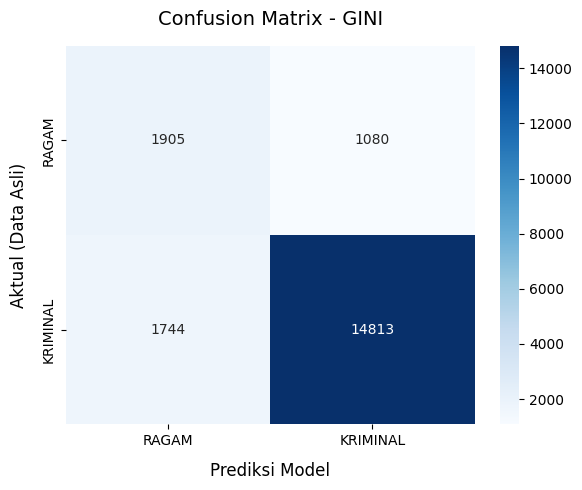


ANGKA CONFUSION MATRIX PAKE SMOTE - GINI
True Negative (Ragam ditebak Ragam)       : 1905
False Positive (Ragam ditebak Kriminal)   : 1080
False Negative (Kriminal ditebak Ragam)   : 1744
True Positive (Kriminal ditebak Kriminal) : 14813


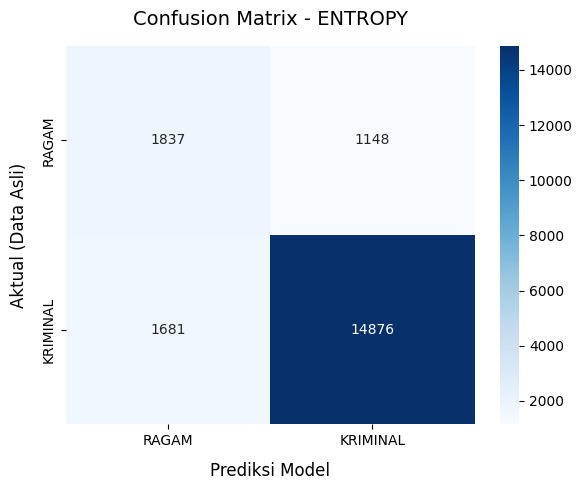


ANGKA CONFUSION MATRIX PAKE SMOTE - ENTROPY
True Negative (Ragam ditebak Ragam)       : 1837
False Positive (Ragam ditebak Kriminal)   : 1148
False Negative (Kriminal ditebak Ragam)   : 1681
True Positive (Kriminal ditebak Kriminal) : 14876


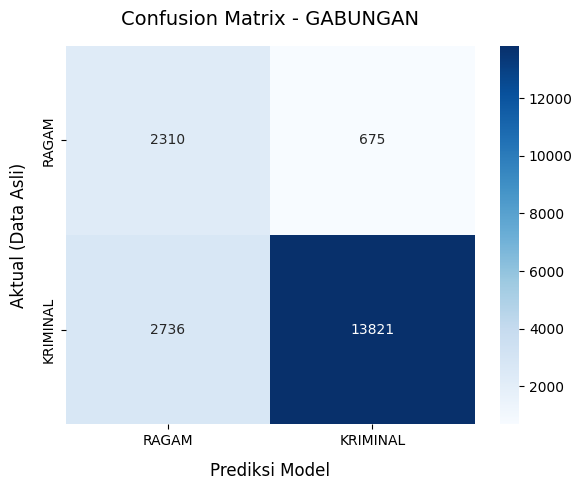


ANGKA CONFUSION MATRIX PAKE SMOTE - GABUNGAN
True Negative (Ragam ditebak Ragam)       : 2310
False Positive (Ragam ditebak Kriminal)   : 675
False Negative (Kriminal ditebak Ragam)   : 2736
True Positive (Kriminal ditebak Kriminal) : 13821


In [24]:
prediksi = {
    'GINI': pred_test_gini,
    'ENTROPY': pred_test_entropy,
    'GABUNGAN': pred_test_gabungan
}
for nama_model, pred in prediksi.items():
    cm = confusion_matrix(y_test, pred)
    
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['RAGAM', 'KRIMINAL'],
        yticklabels=['RAGAM', 'KRIMINAL']
    )

    plt.title(f'Confusion Matrix - {nama_model}', fontsize=14, pad=15)
    plt.xlabel('Prediksi Model', fontsize=12, labelpad=10)
    plt.ylabel('Aktual (Data Asli)', fontsize=12, labelpad=10)
    plt.tight_layout()
    plt.show()
    
    print(f"\nANGKA CONFUSION MATRIX PAKE SMOTE - {nama_model}")
    print(f"True Negative (Ragam ditebak Ragam)       : {cm[0][0]}")
    print(f"False Positive (Ragam ditebak Kriminal)   : {cm[0][1]}")
    print(f"False Negative (Kriminal ditebak Ragam)   : {cm[1][0]}")
    print(f"True Positive (Kriminal ditebak Kriminal) : {cm[1][1]}")

In [25]:
X_all_tfidf = tfidf.transform(df['text_clean'].values)

pred_gini_all = model_gini.predict(X_all_tfidf)
pred_entropy_all = model_entropy.predict(X_all_tfidf)

pred_gabungan_all = []
for g, e in zip(pred_gini_all, pred_entropy_all):
    if g == 1 and e == 1:
        pred_gabungan_all.append(1)
    else:
        pred_gabungan_all.append(0)

df['label_krim_gabungan'] = pred_gabungan_all
df_kriminal_only = df[df['label_krim_gabungan'] == 1].copy()

kolom_pilihan = [
    'judul_berita', 
    'isi_berita', 
    'text_clean', 
    'label_kriminal', 
    'label_krim_gabungan'
]
df_final_csv = df_kriminal_only[kolom_pilihan]
nama_file_csv = 'dataset_kriminal_smote_gabungan2 .csv'
df_final_csv.to_csv(nama_file_csv, index=False, sep=',', encoding='utf-8')

In [26]:
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', 100)       
pd.set_option('display.width', 1000)        
list_berita = [
    "Komplotan pencuri spesialis rumah kosong diamankan polisi setelah beraksi di tiga lokasi berbeda dalam satu minggu",
    "Polda Jabar berhasil menggagalkan upaya pengiriman paket narkoba jenis ganja melalui jasa ekspedisi",
    "Tersangka kasus penganiayaan berat terhadap rekan kerjanya menyerahkan diri ke Mapolres setelah sempat melarikan diri",
    "Seorang pelaku penjambretan tas milik pengendara motor di lampu merah berhasil diringkus warga sebelum diamankan polisi",
    "pelaku pembunuhan berencana terhadap pengusaha muda berhasil ditangkap setelah buron selama tiga bulan",
    "seorang ayah tega menganiaya anak kandung hingga mengalami luka serius akibat persoalan keluarga dilaporkan ke polres",
    "pelaku pencurian uang kotak amal masjid terekam kamera pengawas saat beraksi tengah malam",
    "tim densus 88 mengamankan terduga teroris yang diduga merencanakan aksi pengeboman",
    "pelaku tabrak lari diamankan polisi setelah korban meninggal dunia di lokasi kejadian kasus pidana",
    "sidang kasus perkara tindak pidana pembunuhan berantai kembali digelar dengan agenda pemeriksaan saksi utama",
    "polisi menyita ribuan botol minuman keras ilegal dari gudang distributor tanpa izin resmi",
    "prakiraan cuaca bmkg hari ini tasikmalaya hujan ringan sepanjang sore hari",
    "tips menjaga kesehatan jantung dengan rutin berolahraga dan mengurangi konsumsi makanan berlemak",
    "harga cabai rawit di pasar tradisional mengalami kenaikan akibat cuaca ekstrem dan gagal panen petani",
    "tim nasional indonesia berhasil memenangkan pertandingan semifinal dengan skor dramatis di menit akhir turnamen",
    "warga desa menggelar festival budaya tahunan untuk melestarikan tradisi dan menarik wisatawan asing",
    "dokter menyarankan masyarakat menjaga pola tidur agar terhindar dari gangguan kesehatan mental",
    "petani di garut mulai panen raya jagung setelah musim hujan berlangsung stabil hasil melimpah",
    "wisatawan memadati pantai pangandaran saat libur panjang akhir pekan hotel penuh",
    "bank indonesia mempertahankan suku bunga acuan guna menjaga stabilitas ekonomi nasional keuangan",
    "universitas indonesia membuka program beasiswa baru untuk mahasiswa berprestasi dari daerah terpencil",
    "aktivitas gunung merapi meningkat dan warga diminta waspada terhadap potensi erupsi bencana alam",
]
hasil_prediksi = []
for teks in list_berita:
    vektor = tfidf.transform([teks.lower()])
    pred_g = model_gini.predict(vektor)[0]
    pred_e = model_entropy.predict(vektor)[0]

    if pred_g == 1 and pred_e == 1:
        label = "KRIMINAL"
    else:
        label = "RAGAM"
        
    hasil_prediksi.append({
        'Teks Berita': teks, 
        'Prediksi Gini': "KRIMINAL" if pred_g == 1 else "RAGAM",
        'Prediksi Entropy': "KRIMINAL" if pred_e == 1 else "RAGAM",
        'Hasil Akhir Gabungan': label
    })

df_hasil = pd.DataFrame(hasil_prediksi)
df_hasil

,Teks Berita,Prediksi Gini,Prediksi Entropy,Hasil Akhir Gabungan
0,Komplotan pencuri spesialis rumah kosong diamankan polisi setelah beraksi di tiga lokasi berbeda dalam satu minggu,RAGAM,KRIMINAL,RAGAM
1,Polda Jabar berhasil menggagalkan upaya pengiriman paket narkoba jenis ganja melalui jasa ekspedisi,KRIMINAL,KRIMINAL,KRIMINAL
2,Tersangka kasus penganiayaan berat terhadap rekan kerjanya menyerahkan diri ke Mapolres setelah sempat melarikan diri,KRIMINAL,KRIMINAL,KRIMINAL
3,Seorang pelaku penjambretan tas milik pengendara motor di lampu merah berhasil diringkus warga sebelum diamankan polisi,KRIMINAL,KRIMINAL,KRIMINAL
4,pelaku pembunuhan berencana terhadap pengusaha muda berhasil ditangkap setelah buron selama tiga bulan,KRIMINAL,KRIMINAL,KRIMINAL
5,seorang ayah tega menganiaya anak kandung hingga mengalami luka serius akibat persoalan keluarga dilaporkan ke polres,KRIMINAL,KRIMINAL,KRIMINAL
6,pelaku pencurian uang kotak amal masjid terekam kamera pengawas saat beraksi tengah malam,KRIMINAL,KRIMINAL,KRIMINAL
7,tim densus 88 mengamankan terduga teroris yang diduga merencanakan aksi pengeboman,KRIMINAL,KRIMINAL,KRIMINAL
8,pelaku tabrak lari diamankan polisi setelah korban meninggal dunia di lokasi kejadian kasus pidana,KRIMINAL,KRIMINAL,KRIMINAL
9,sidang kasus perkara tindak pidana pembunuhan berantai kembali digelar dengan agenda pemeriksaan saksi utama,KRIMINAL,KRIMINAL,KRIMINAL
